# Problem Statement

The dataset contains 6 years of information(weekly stock information) on the stock prices of 10 different Indian Stocks. Calculate the mean and standard deviation on the stock returns and share insights.
Please find attached the files to be referred.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn.metrics as metrics

# Dataset Loading and Exploration

In [2]:
stock_prices = pd.read_csv('Market+Risk+Dataset.csv')
stock_prices.head()

,Date,Infosys,Indian Hotel,Mahindra & Mahindra,Axis Bank,SAIL,Shree Cement,Sun Pharma,Jindal Steel,Idea Vodafone,Jet Airways
0,31-03-2014,264,69,455,263,68,5543,555,298,83,278
1,07-04-2014,257,68,458,276,70,5728,610,279,84,303
2,14-04-2014,254,68,454,270,68,5649,607,279,83,280
3,21-04-2014,253,68,488,283,68,5692,604,274,83,282
4,28-04-2014,256,65,482,282,63,5582,611,238,79,243


In [10]:
stock_prices.tail()

,Date,Infosys,Indian_Hotel,Mahindra_and_Mahindra,Axis_Bank,SAIL,Shree_Cement,Sun_Pharma,Jindal_Steel,Idea_Vodafone,Jet_Airways
309,02-03-2020,729,120,469,658,33,23110,401,146,3,22
310,09-03-2020,634,114,427,569,30,21308,384,121,6,18
311,16-03-2020,577,90,321,428,27,18904,365,105,3,16
312,23-03-2020,644,75,293,360,21,17666,338,89,3,14
313,30-03-2020,633,75,284,379,23,17546,352,82,3,14


The stock prices dataset has columns with special characters and spaces.  Let's correct the column names for easy readability and reference.

In [4]:
stock_prices.columns = stock_prices.columns.str.strip().str.replace(' ','_').str.replace('&','and')
stock_prices.head()

,Date,Infosys,Indian_Hotel,Mahindra_and_Mahindra,Axis_Bank,SAIL,Shree_Cement,Sun_Pharma,Jindal_Steel,Idea_Vodafone,Jet_Airways
0,31-03-2014,264,69,455,263,68,5543,555,298,83,278
1,07-04-2014,257,68,458,276,70,5728,610,279,84,303
2,14-04-2014,254,68,454,270,68,5649,607,279,83,280
3,21-04-2014,253,68,488,283,68,5692,604,274,83,282
4,28-04-2014,256,65,482,282,63,5582,611,238,79,243


As shown above, the column names of stock prices dataset has been corrected for easy readability.  Let's observe the shape of the stock prices dataset now.

In [5]:
print('The number of rows (observations): ',stock_prices.shape[0],'\n''The number of columns (variables): ',stock_prices.shape[1])

The number of rows (observations):  314 
The number of columns (variables):  11


Let's now check the data types of variables in stock prices dataset.

In [6]:
stock_prices.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 314 entries, 0 to 313
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Date                   314 non-null    object
 1   Infosys                314 non-null    int64 
 2   Indian_Hotel           314 non-null    int64 
 3   Mahindra_and_Mahindra  314 non-null    int64 
 4   Axis_Bank              314 non-null    int64 
 5   SAIL                   314 non-null    int64 
 6   Shree_Cement           314 non-null    int64 
 7   Sun_Pharma             314 non-null    int64 
 8   Jindal_Steel           314 non-null    int64 
 9   Idea_Vodafone          314 non-null    int64 
 10  Jet_Airways            314 non-null    int64 
dtypes: int64(10), object(1)
memory usage: 27.1+ KB


Let's check for the basic measures of descriptive statistics of continuous variables in the stock prices dataset.

In [7]:
stock_prices.describe()

,Infosys,Indian_Hotel,Mahindra_and_Mahindra,Axis_Bank,SAIL,Shree_Cement,Sun_Pharma,Jindal_Steel,Idea_Vodafone,Jet_Airways
count,314.000000,314.000000,314.000000,314.000000,314.000000,314.000000,314.000000,314.000000,314.000000,314.000000
mean,511.340764,114.560510,636.678344,540.742038,59.095541,14806.410828,633.468153,147.627389,53.713376,372.659236
std,135.952051,22.509732,102.879975,115.835569,15.810493,4288.275085,171.855893,65.879195,31.248985,202.262668
min,234.000000,64.000000,284.000000,263.000000,21.000000,5543.000000,338.000000,53.000000,3.000000,14.000000
25%,424.000000,96.000000,572.000000,470.500000,47.000000,10952.250000,478.500000,88.250000,25.250000,243.250000
50%,466.500000,115.000000,625.000000,528.000000,57.000000,16018.500000,614.000000,142.500000,53.000000,376.000000
75%,630.750000,134.000000,678.000000,605.250000,71.750000,17773.250000,785.000000,182.750000,82.000000,534.000000
max,810.000000,157.000000,956.000000,808.000000,104.000000,24806.000000,1089.000000,338.000000,117.000000,871.000000


In [8]:
stock_prices.duplicated().sum()

0

In [9]:
stock_prices.isnull().sum()

Date                     0
Infosys                  0
Indian_Hotel             0
Mahindra_and_Mahindra    0
Axis_Bank                0
SAIL                     0
Shree_Cement             0
Sun_Pharma               0
Jindal_Steel             0
Idea_Vodafone            0
Jet_Airways              0
dtype: int64

The stock prices dataset deals with weekly stock prices of 10 companies from beginning of financial year 2014 till end of financial year 2019 (March 2020).

The dataset has 314 rows and 11 columns (variables).  The first column of the dataset is Date and each of the remaining columns belongs to a company.

Out of 11 variables of the stock prices dataset, one variable Date is of object data type.  All the remaining 10 variables are of int64 data type.  These 10 variables have stock prices data for a company each.

The stock prices dataset has neither duplicate values nor null values, hence, safe for further processing.  

# Market Risk Analysis

## Draw Stock Price Chart for any 2 variables

One of the prominent methods for analyzing the stock prices data of companies is to plot the stock prices against the time series like daily, weekly, monthly etc.  Let's plot the stock prices data of some specific companies from stock prices dataset against the time series.

In [11]:
def draw_stock_price(company):
    plt.figure(figsize = (10, 8))
    stock_prices['dates'] = [pd.to_datetime(d) for d in stock_prices['Date']]
    plt.scatter(stock_prices['dates'], stock_prices[company], edgecolors='r')
    plt.xlabel('Year')
    plt.ylabel(company)
    plt.title('Year vs {}'.format(company))
    plt.show()

Now, let's draw the stock price chart for Infosys and Shree_Cement.

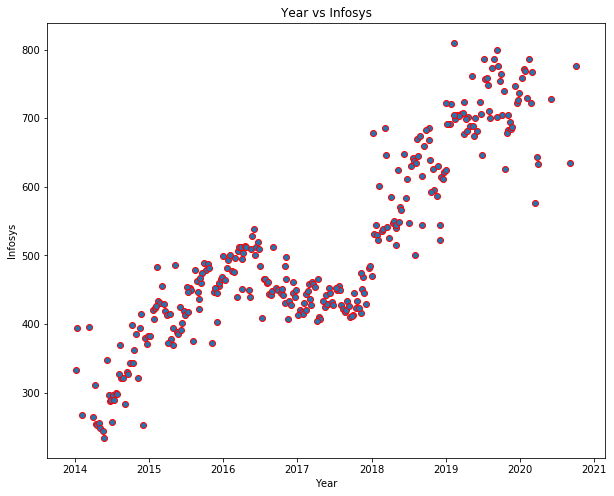

In [12]:
draw_stock_price('Infosys')

From the above stock price chart for Infosys,`
There is a gradual increase in stock price value for Infosys from the year 2014 to the year 2020, except that there is a slight decrease in stock price during the beginning of the year 2017 and the same stock price remains without any increase or decrease until the end of the year 2017.  From 2018 onwards, the stock price again started increasing until 2020.

The stock price of Infosys starts at the minimum value of 234 and reached upto the maximum value of 810 between the year frame from 2013 to 2020.  This is a significant increase of stock price overall.  

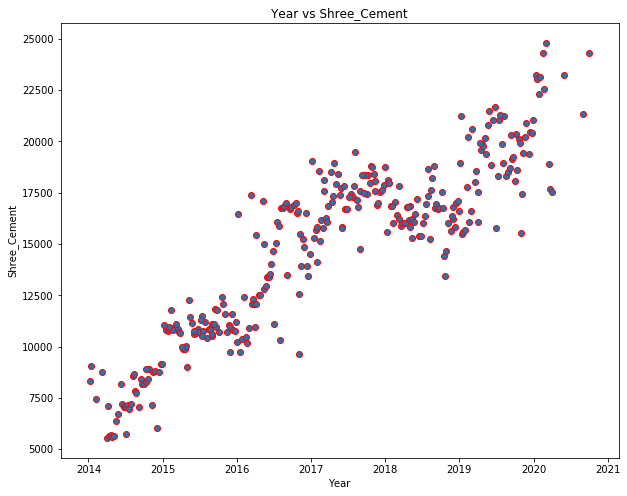

In [13]:
draw_stock_price('Shree_Cement')

From the above stock price chart for Shree_Cement,` There is a gradual increase in stock price value for Shree_Cement from the year 2014 to the year 2020, except that there is a slight decrease in stock price during the beginning of the year 2018 and the same stock price remains without any increase or decrease until the end of the year 2019. From 2019 onwards, the stock price again started increasing until 2020.

The stock price of Shree_Cement starts at the minimum value of 5543 and reached upto the maximum value of 24806 between the year frame from 2013 to 2020. This is a significant increase of stock price overall.

## Calculate Returns

Next to the detailed analysis of stock prices over a period of time, the calculation of returns is one of the critical steps in the market risk analysis.  

Overall, the calculation returns from the stock prices data is a step process.  The steps are
1. Take logarithms for the variables with stock prices data excluding any time series columns.
2. Then, take differences with specific period value.

Now, let's calculate returns for the stock prices dataset.

In [16]:
stock_returns = np.log(stock_prices.drop(['Date', 'dates'], axis=1)).diff(axis = 0, periods = 1)

The stock returns data has only 10 variables the time series variable has been excluded for returns calculation.  Also, the stock returns dataset has the same number of rows as original stock prices dataset but the first row has only null values, as we take rolling differences between rows.

The shape of the stock_returns dataset is

In [18]:
print('The shape of the stock returns dataset: {}'.format(stock_returns.shape))

The shape of the stock returns dataset: (314, 10)


In [19]:
stock_returns.head()

,Infosys,Indian_Hotel,Mahindra_and_Mahindra,Axis_Bank,SAIL,Shree_Cement,Sun_Pharma,Jindal_Steel,Idea_Vodafone,Jet_Airways
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,-0.026873,-0.014599,0.006572,0.048247,0.028988,0.032831,0.094491,-0.065882,0.011976,0.086112
2,-0.011742,0.000000,-0.008772,-0.021979,-0.028988,-0.013888,-0.004930,0.000000,-0.011976,-0.078943
3,-0.003945,0.000000,0.072218,0.047025,0.000000,0.007583,-0.004955,-0.018084,0.000000,0.007117
4,0.011788,-0.045120,-0.012371,-0.003540,-0.076373,-0.019515,0.011523,-0.140857,-0.049393,-0.148846


## Calculate Stock Means and Standard Deviation

Next to the calculation of stock returns from the stock prices data, the calculation of stock means and stock standard deviation from the stock returns data is one of the critical steps in the market risk analysis.

The calculation calculation of stock means and stock standard deviation from the stock returns data is straight-forward.

1. Stock Means: This indicates the average returns that the stock is making on a week to week basis.
2. Stock Standard Deviation: This is a measure of volatility that the more a stock's returns vary from the stock's average return, the more volatile the stock. 

Now, let's calculate the stock means and stock standard deviation from the stock returns data.

### Stock Means and Stock Standard Deviation

In [23]:
stock_means = stock_returns.mean(axis = 0)
stock_means

Infosys                  0.002794
Indian_Hotel             0.000266
Mahindra_and_Mahindra   -0.001506
Axis_Bank                0.001167
SAIL                    -0.003463
Shree_Cement             0.003681
Sun_Pharma              -0.001455
Jindal_Steel            -0.004123
Idea_Vodafone           -0.010608
Jet_Airways             -0.009548
dtype: float64

In [25]:
stock_stddev = stock_returns.std(axis = 0)
stock_stddev

Infosys                  0.035070
Indian_Hotel             0.047131
Mahindra_and_Mahindra    0.040169
Axis_Bank                0.045828
SAIL                     0.062188
Shree_Cement             0.039917
Sun_Pharma               0.045033
Jindal_Steel             0.075108
Idea_Vodafone            0.104315
Jet_Airways              0.097972
dtype: float64

From the stock mean and stock standard deviation numbers above,
1. The companies Mahindra, SAIL, Sun pharma, Jindal steel, Idea vodafone, and Jet airways shows negative average returns. The remaining companies shows positive returns.
2. Companies Shree cement and Infosys take the first and second places respectively with respect to highest average stock returns.
3. In terms of stock standard deviation, Idea vodafone and Jet airways take first and second places respectively with respect to highest standard deviation.  The companies Infosys and Shree cement have the lower standard deviations when compared to other companies.

## Draw a plot of Stock Means vs Standard Deviation and share insights

### Stock Means vs Standard Deviation Plot

As the stock means and stock standard deviations have been calculated, the next step is to plot them to find out the status of companies from various perspectives like high risk, low risk, high returns, low returns etc.

Let's plot the stock means and stock standard deviations data to get more insights.

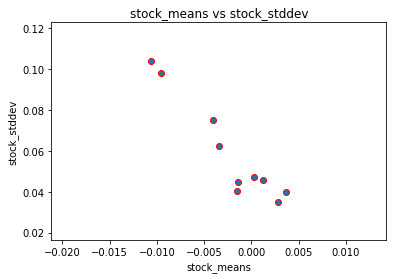

In [28]:
plt.scatter(stock_means, stock_stddev, edgecolors='r')
plt.xlabel('stock_means')
plt.ylabel('stock_stddev')
plt.title('stock_means vs stock_stddev')
plt.show()

### Insights

From the above plot of stock means and stock standard deviation,
1. In general, the stocks with a lower mean & higher standard deviation do not play a role in a portfolio that has competing stock with more returns & less risk. The stocks with higher mean and lower standard deviation would be the better ones ie. they are the ones that belong to higher returns and lower risk.
2. It is clear from the plot that the stocks with lower means have higher standard deviation.  As the mean started increasing, the standard deviation starts decreasing.
3. There are two companies in the top of the plot with higher standard deviation and lower mean.  These are Idea Vodafone and Jet Airways.
4. There are two companies in the bottom right of the plot with higher mean and lower standard deviation.  These are Infosys and Shree Cement.

Overall from pure Returns perspective, Shree cement looks good in this dataset followed by Infosys. From pure Risk perspective also(as measured by standard deviation), Infosys followed by Shree cement looks good in this dataset.